In [186]:
import pandas as pd
import hashlib
import matplotlib.pyplot as plt
import re
import numpy as np
import pandas as pd
import seaborn as sns

# Основной сегмент (не вахта / удаленка)

In [187]:
df = pd.read_csv('vacancies.csv')

df.shape
print(df.isna().sum())
print(df['profession'].isna().sum())
print(df['profession_resolved'].isna().sum())

/tmp/ipykernel_1754/1172967237.py:1: DtypeWarning:

Columns (77,88,91,101,103,107,109,110) have mixed types. Specify dtype option on import or set low_memory=False.



source                    0
id                        0
city                   9027
region                 4801
profession             9404
                      ...  
run_id                    0
run_ids                   0
enrichment_status         0
enriched_fields       23036
enrichment_version    23036
Length: 127, dtype: int64
9404
7917


In [188]:
print(df['city'].isna().sum())
print(df['city_resolved'].isna().sum())

9027
222


In [189]:
df['Формат работы'].value_counts()

,count
Формат работы,
Удалённо,1938
В офисе или на объекте,374
"Удалённо, В офисе или на объекте, Гибрид",157
"Удалённо, В офисе или на объекте",150
"Удалённо, Гибрид",101
"Удалённо, В офисе или на объекте, Гибрид, Разъездной формат",66
"Удалённо, Разъездной формат",39
"Удалённо, В офисе или на объекте, Разъездной формат",20
Разъездной формат,14


In [190]:
df['График'].unique()

array(['Фиксированный', 'Сменный', 'Вахта', 'Гибкий'], dtype=object)

In [191]:
df.head()

,source,id,city,region,profession,segments,title,salary_raw,source_url,observed_at,...,city_resolved,city_resolved_source,labels_rule_version,first_seen_at,last_seen_at,run_id,run_ids,enrichment_status,enriched_fields,enrichment_version
0,avito,1001452517,Санкт-Петербург,Санкт-Петербург,NaN,NaN,Менеджер-дизайнер в фото-копицентр,55 000 — 65 000 ₽ \nна руки,https://www.avito.ru/sankt-peterburg/vakansii/...,2026-10-28T18:38:37.202Z,...,Санкт-Петербург,card,vacancy_labels_v2,2026-10-28T18:38:37.202Z,2026-10-28T18:38:37.202Z,spb_all_first1500_2026-10-28,spb_all_first1500_2026-10-28,not_run,NaN,NaN
1,avito,1004619500,Санкт-Петербург,Санкт-Петербург,Водитель грузового транспорта,NaN,Набор водителей (категорияС) камаз-пухтовоз,от 120 000 ₽,https://www.avito.ru/sankt-peterburg/vakansii/...,2026-10-29T11:04:16.043Z,...,Санкт-Петербург,card,vacancy_labels_v2,2026-10-29T11:04:16.043Z,2026-10-29T11:04:16.043Z,20261029_sp_driver17_part_02,20261029_sp_driver17_part_02,not_run,NaN,NaN
2,avito,1012505611,Санкт-Петербург,Санкт-Петербург,NaN,NaN,Продавец консультант,2 500 — 3 000 ₽ \nза смену на руки,https://www.avito.ru/sankt-peterburg/vakansii/...,2026-10-28T18:40:49.897Z,...,Санкт-Петербург,card,vacancy_labels_v2,2026-10-28T18:40:49.897Z,2026-10-28T18:40:49.897Z,spb_all_first1500_2026-10-28,spb_all_first1500_2026-10-28,not_run,NaN,NaN
3,avito,1016310090,Москва,Москва,NaN,NaN,Водитель самосвала вахта,250 000 — 300 000 ₽ \nна руки,https://www.avito.ru/moskva/vakansii/voditel_s...,2026-11-02T19:56:32.183Z,...,Москва,card,vacancy_labels_v2,2026-11-02T19:56:32.183Z,2026-11-02T19:56:32.183Z,vahta_1500_2026-11-02_sasha,vahta_1500_2026-11-02_sasha,not_run,NaN,NaN
4,avito,1026728665,NaN,NaN,Грузчик,NaN,Грузчик. Заработная плата,55 000 — 70 000 ₽,https://www.avito.ru/krymsk/vakansii/gruzchik....,2026-11-03T14:32:28.779Z,...,Крымск,location_observed,vacancy_labels_v2,2026-11-03T14:32:28.779Z,2026-11-03T14:32:28.779Z,avito_20261102_gruzchik_all_1500,avito_20261102_gruzchik_all_1500,not_run,NaN,NaN


In [192]:
df = df[(df['График'] != "Вахта") & (df['Формат работы'] != "Удаленно" )]

In [193]:
print(df['profession'].unique())

[nan 'Водитель грузового транспорта' 'Грузчик' 'Продавец' 'Кассир'
 'Курьер' 'Комплектовщик' 'Продавец; Кассир']


In [194]:
print(df['region'].value_counts())

region
Москва                   6350
Санкт-Петербург          5479
Свердловская область     2187
Камчатский край           736
Московская область        389
Новосибирская область      85
Челябинская область        49
Ленинградская область      46
Тверская область           24
Орловская область          22
Name: count, dtype: int64


In [195]:
print(df['city_resolved'].value_counts())

city_resolved
Москва                      6249
Санкт-Петербург             5478
Екатеринбург                2123
Петропавловск-Камчатский     564
Самара                       384
                            ... 
Лукоянов                       1
Лыткарино                      1
Лисичанск                      1
д. Переделки                   1
пгт. Правдинский               1
Name: count, Length: 590, dtype: int64


In [196]:
for i, column in enumerate(df.columns):
    print(f"{i}. {column}")

0. source
1. id
2. city
3. region
4. profession
5. segments
6. title
7. salary_raw
8. source_url
9. observed_at
10. description
11. location_observed
12. employer_name_observed
13. date_raw
14. views_total
15. views_today
16. listing_rank
17. listing_promoted
18. full_parameters_read
19. analysis_status
20. export_eligibility
21. read_status_parameters
22. read_status_description
23. read_status_location
24. read_limitations
25. city__source
26. city__evidence
27. city_anomaly
28. График
29. Занятость
30. Способ оформления
31. Количество рабочих часов в день
32. Частота выплат
33. Сфера деятельности компании
34. Что получают работники
35. Смены
36. Ассортимент
37. Опыт работы
38. В том числе для кандидатов
39. Медкнижка
40. Объект
41. Опыт военной службы
42. Навыки обращения с оружием
43. Количество рабочих дней в неделю
44. Тип предприятия
45. Длительность вахты
46. Инструменты
47. Тип работ
48. Можно заканчивать в 17:00
49. Формат работы
50. Режим работы
51. Навык ремонта техники
52.

In [197]:
df['Частота выплат'].unique()

array(['Раз в неделю', 'Дважды в месяц', 'Каждый день', nan,
       'Дважды в\xa0месяц', 'Три раза в месяц', 'Раз в месяц',
       'Раз в\xa0неделю', 'Три раза в\xa0месяц', 'Раз в\xa0месяц'],
      dtype=object)

In [198]:
SALARY_RE = re.compile(
    r"(?:(от|до)\s+)?"
    r"(\d[\d ]*)"
    r"(?:\s*[—–-]\s*(\d[\d ]*))?"
    r"\s*₽"
    r"(?:\s+(за смену|в час|за час|в неделю|за день|в месяц|за месяц|месяц|сдельно))?"
    r"(?:\s+(на руки|до вычета налогов))?",
    re.IGNORECASE,
)

UNITS = {
    "за смену": "shift",
    "в час": "hour",
    "за час": "hour",
    "в неделю": "week",
    "за день": "day",
    "в месяц": "month",
    "месяц": "month",
    "за месяц": "month",
    "сдельно": "piecework",
}

def parse_salary(value):
    result = {
        "salary_min_rub": np.nan,
        "salary_max_rub": np.nan,
        "salary_unit": "unspecified",
        "salary_tax": "unknown",
        "salary_shape": "unknown",
        "salary_parse_status": "unrecognized",
    }

    if pd.isna(value):
        result["salary_parse_status"] = "missing"
        return result

    text = re.sub(r"\s+", " ", str(value).replace("\ufeff", " ")).strip()
    if not text or text.casefold() == "зарплата не указана":
        result["salary_parse_status"] = "missing"
        return result

    match = SALARY_RE.fullmatch(text)
    if match is None:
        return result

    bound, first, second, unit, tax = match.groups()
    bound = bound.casefold() if bound else None
    first = int(first.replace(" ", ""))
    second = int(second.replace(" ", "")) if second else None

    if (second is not None and second < first) or (bound and second is not None):
        return result

    if bound == "от":
        result["salary_min_rub"] = first
        result["salary_shape"] = "from"
    elif bound == "до":
        result["salary_max_rub"] = first
        result["salary_shape"] = "to"
    elif second is not None:
        result["salary_min_rub"] = first
        result["salary_max_rub"] = second
        result["salary_shape"] = "range"
    else:
        result["salary_min_rub"] = first
        result["salary_max_rub"] = first
        result["salary_shape"] = "exact"

    if unit:
        result["salary_unit"] = UNITS[unit.casefold()]
    if tax:
        result["salary_tax"] = (
            "net" if tax.casefold() == "на руки" else "gross"
        )

    result["salary_parse_status"] = (
        "review_zero_lower_bound" if first == 0 else "parsed"
    )
    return result


parsed = pd.DataFrame(df["salary_raw"].map(parse_salary).tolist(), index=df.index,)
df = pd.concat([df, parsed], axis=1)
df.head()


,source,id,city,region,profession,segments,title,salary_raw,source_url,observed_at,...,run_ids,enrichment_status,enriched_fields,enrichment_version,salary_min_rub,salary_max_rub,salary_unit,salary_tax,salary_shape,salary_parse_status
0,avito,1001452517,Санкт-Петербург,Санкт-Петербург,NaN,NaN,Менеджер-дизайнер в фото-копицентр,55 000 — 65 000 ₽ \nна руки,https://www.avito.ru/sankt-peterburg/vakansii/...,2026-10-28T18:38:37.202Z,...,spb_all_first1500_2026-10-28,not_run,NaN,NaN,55000.0,65000.0,unspecified,net,range,parsed
1,avito,1004619500,Санкт-Петербург,Санкт-Петербург,Водитель грузового транспорта,NaN,Набор водителей (категорияС) камаз-пухтовоз,от 120 000 ₽,https://www.avito.ru/sankt-peterburg/vakansii/...,2026-10-29T11:04:16.043Z,...,20261029_sp_driver17_part_02,not_run,NaN,NaN,120000.0,NaN,unspecified,unknown,from,parsed
2,avito,1012505611,Санкт-Петербург,Санкт-Петербург,NaN,NaN,Продавец консультант,2 500 — 3 000 ₽ \nза смену на руки,https://www.avito.ru/sankt-peterburg/vakansii/...,2026-10-28T18:40:49.897Z,...,spb_all_first1500_2026-10-28,not_run,NaN,NaN,2500.0,3000.0,shift,net,range,parsed
4,avito,1026728665,NaN,NaN,Грузчик,NaN,Грузчик. Заработная плата,55 000 — 70 000 ₽,https://www.avito.ru/krymsk/vakansii/gruzchik....,2026-11-03T14:32:28.779Z,...,avito_20261102_gruzchik_all_1500,not_run,NaN,NaN,55000.0,70000.0,unspecified,unknown,range,parsed
5,avito,1032652711,NaN,NaN,Грузчик,NaN,Грузчик - на производство,76 000 — 80 000 ₽ \nна руки,https://www.avito.ru/naberezhnye_chelny/vakans...,2026-11-03T11:56:51.184Z,...,avito_20261102_gruzchik_all_1500,not_run,NaN,NaN,76000.0,80000.0,unspecified,net,range,parsed


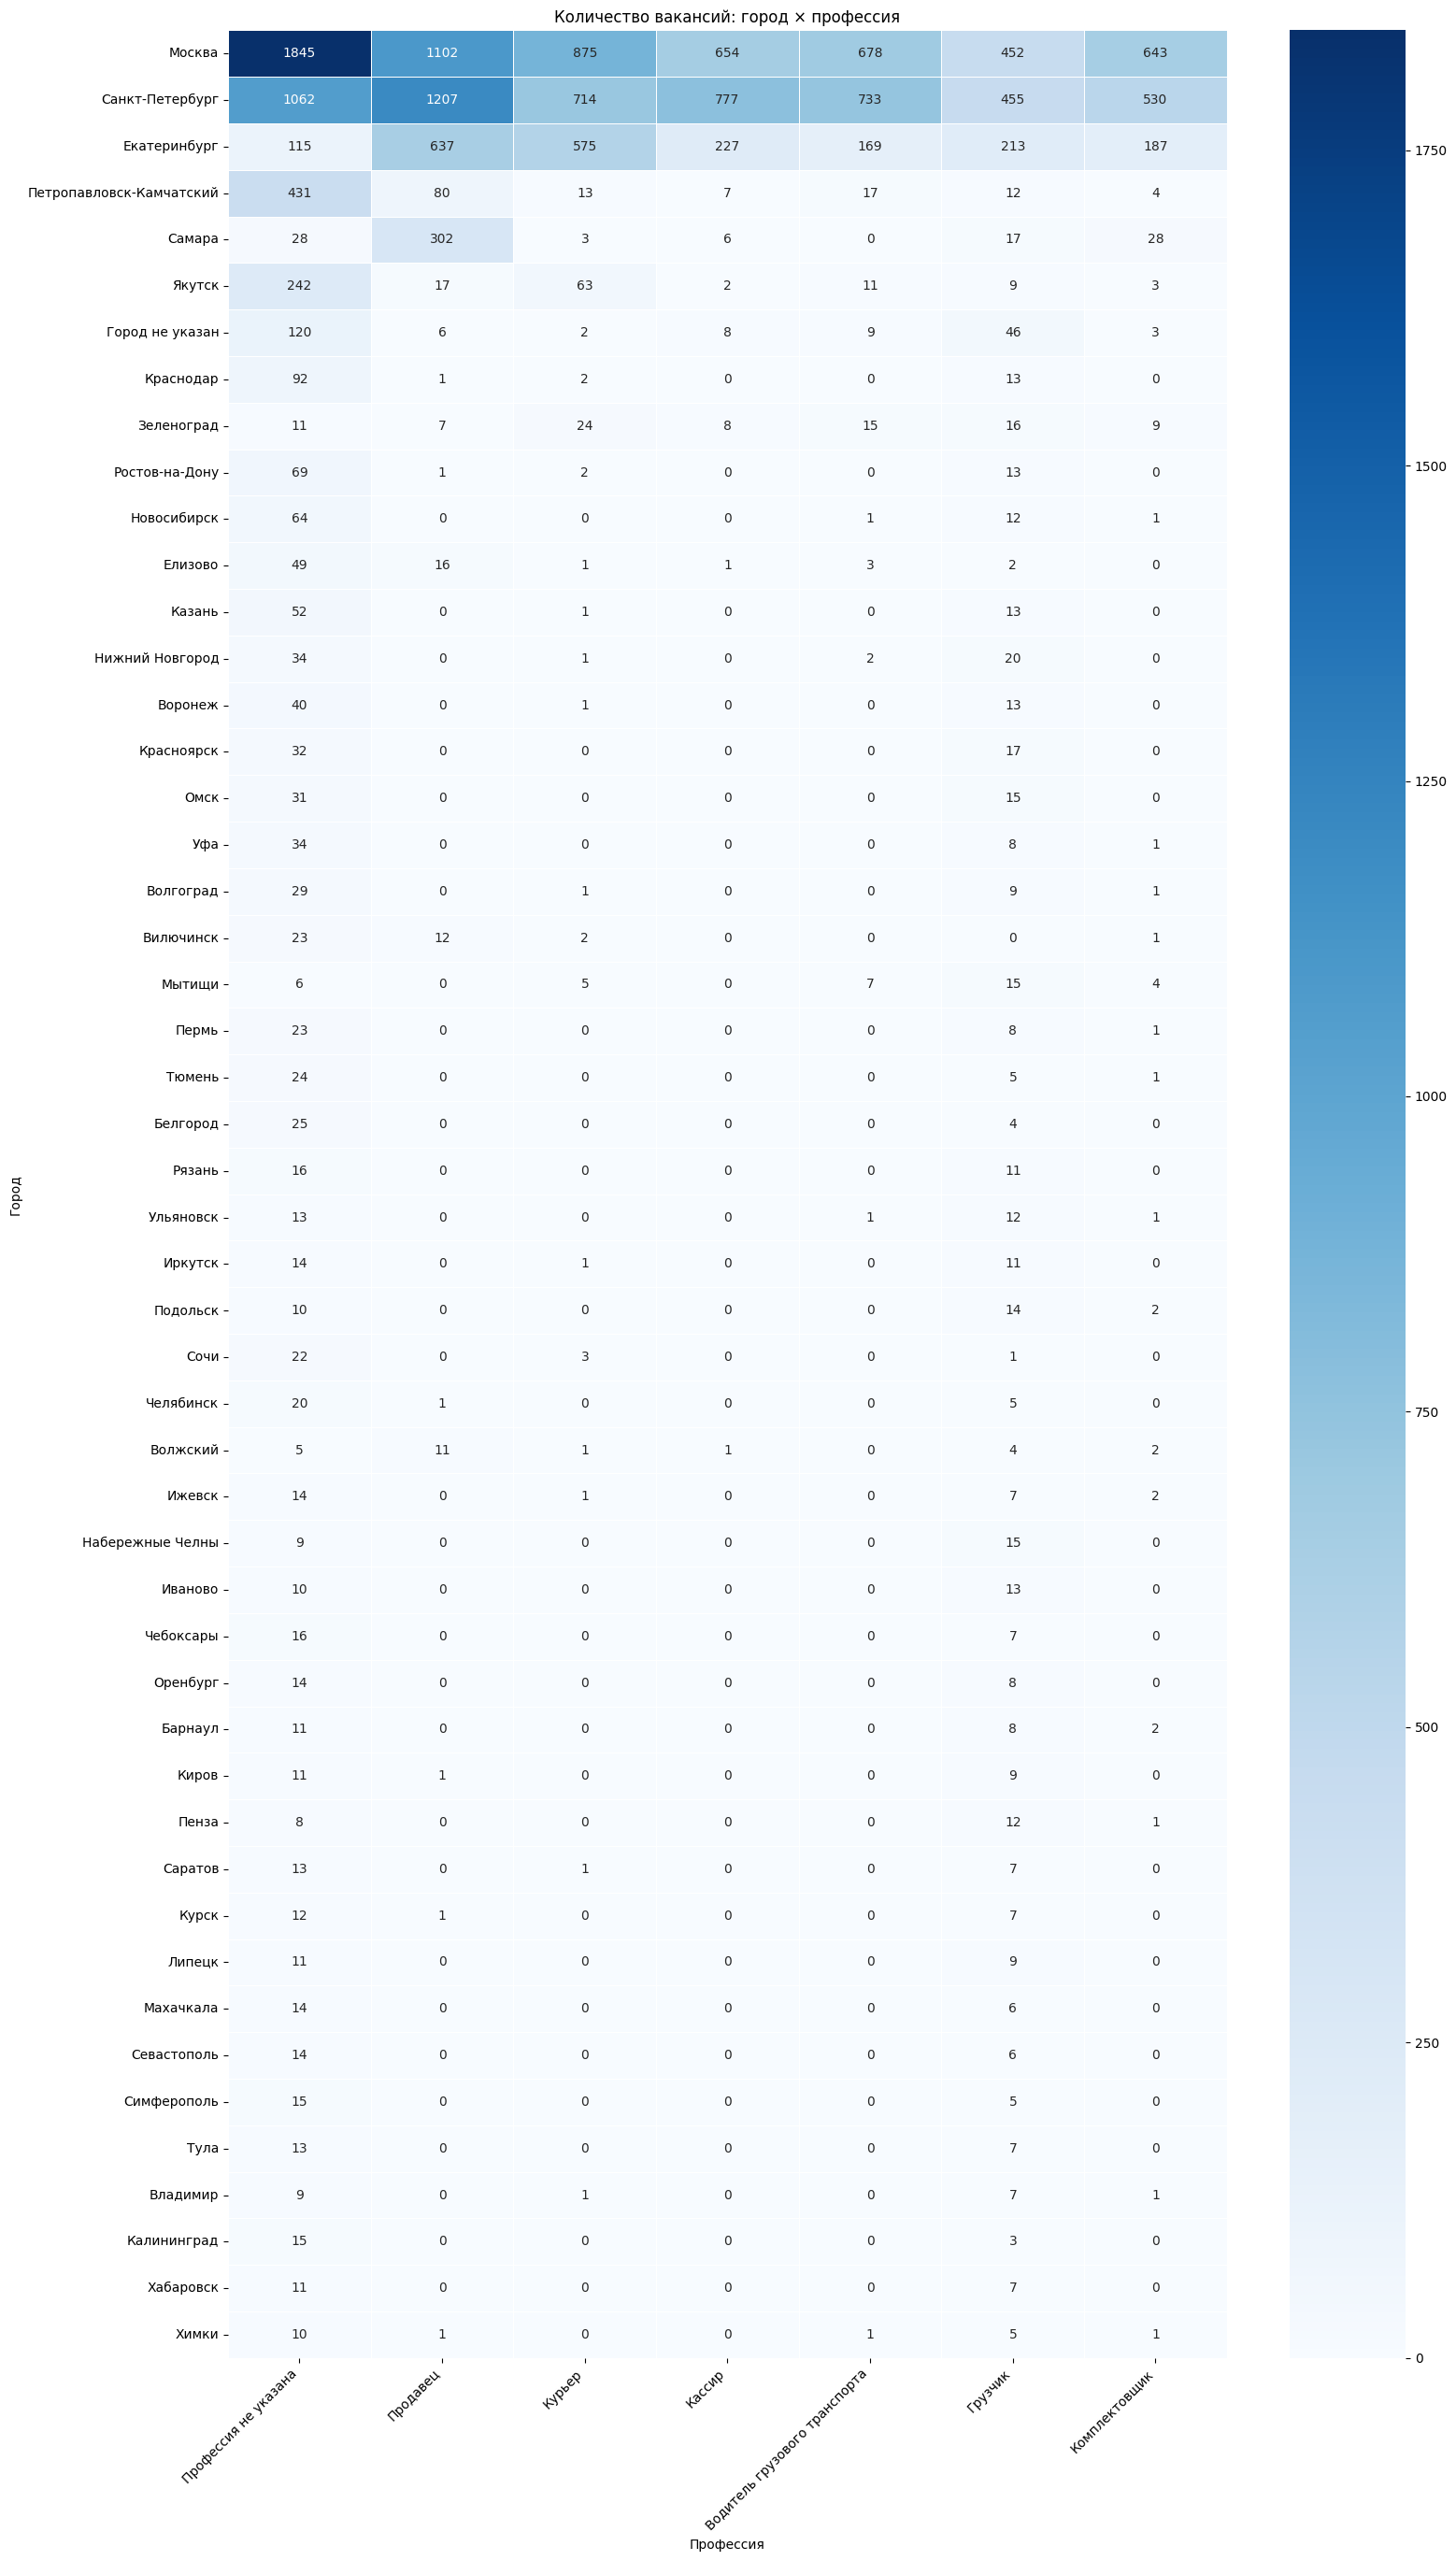

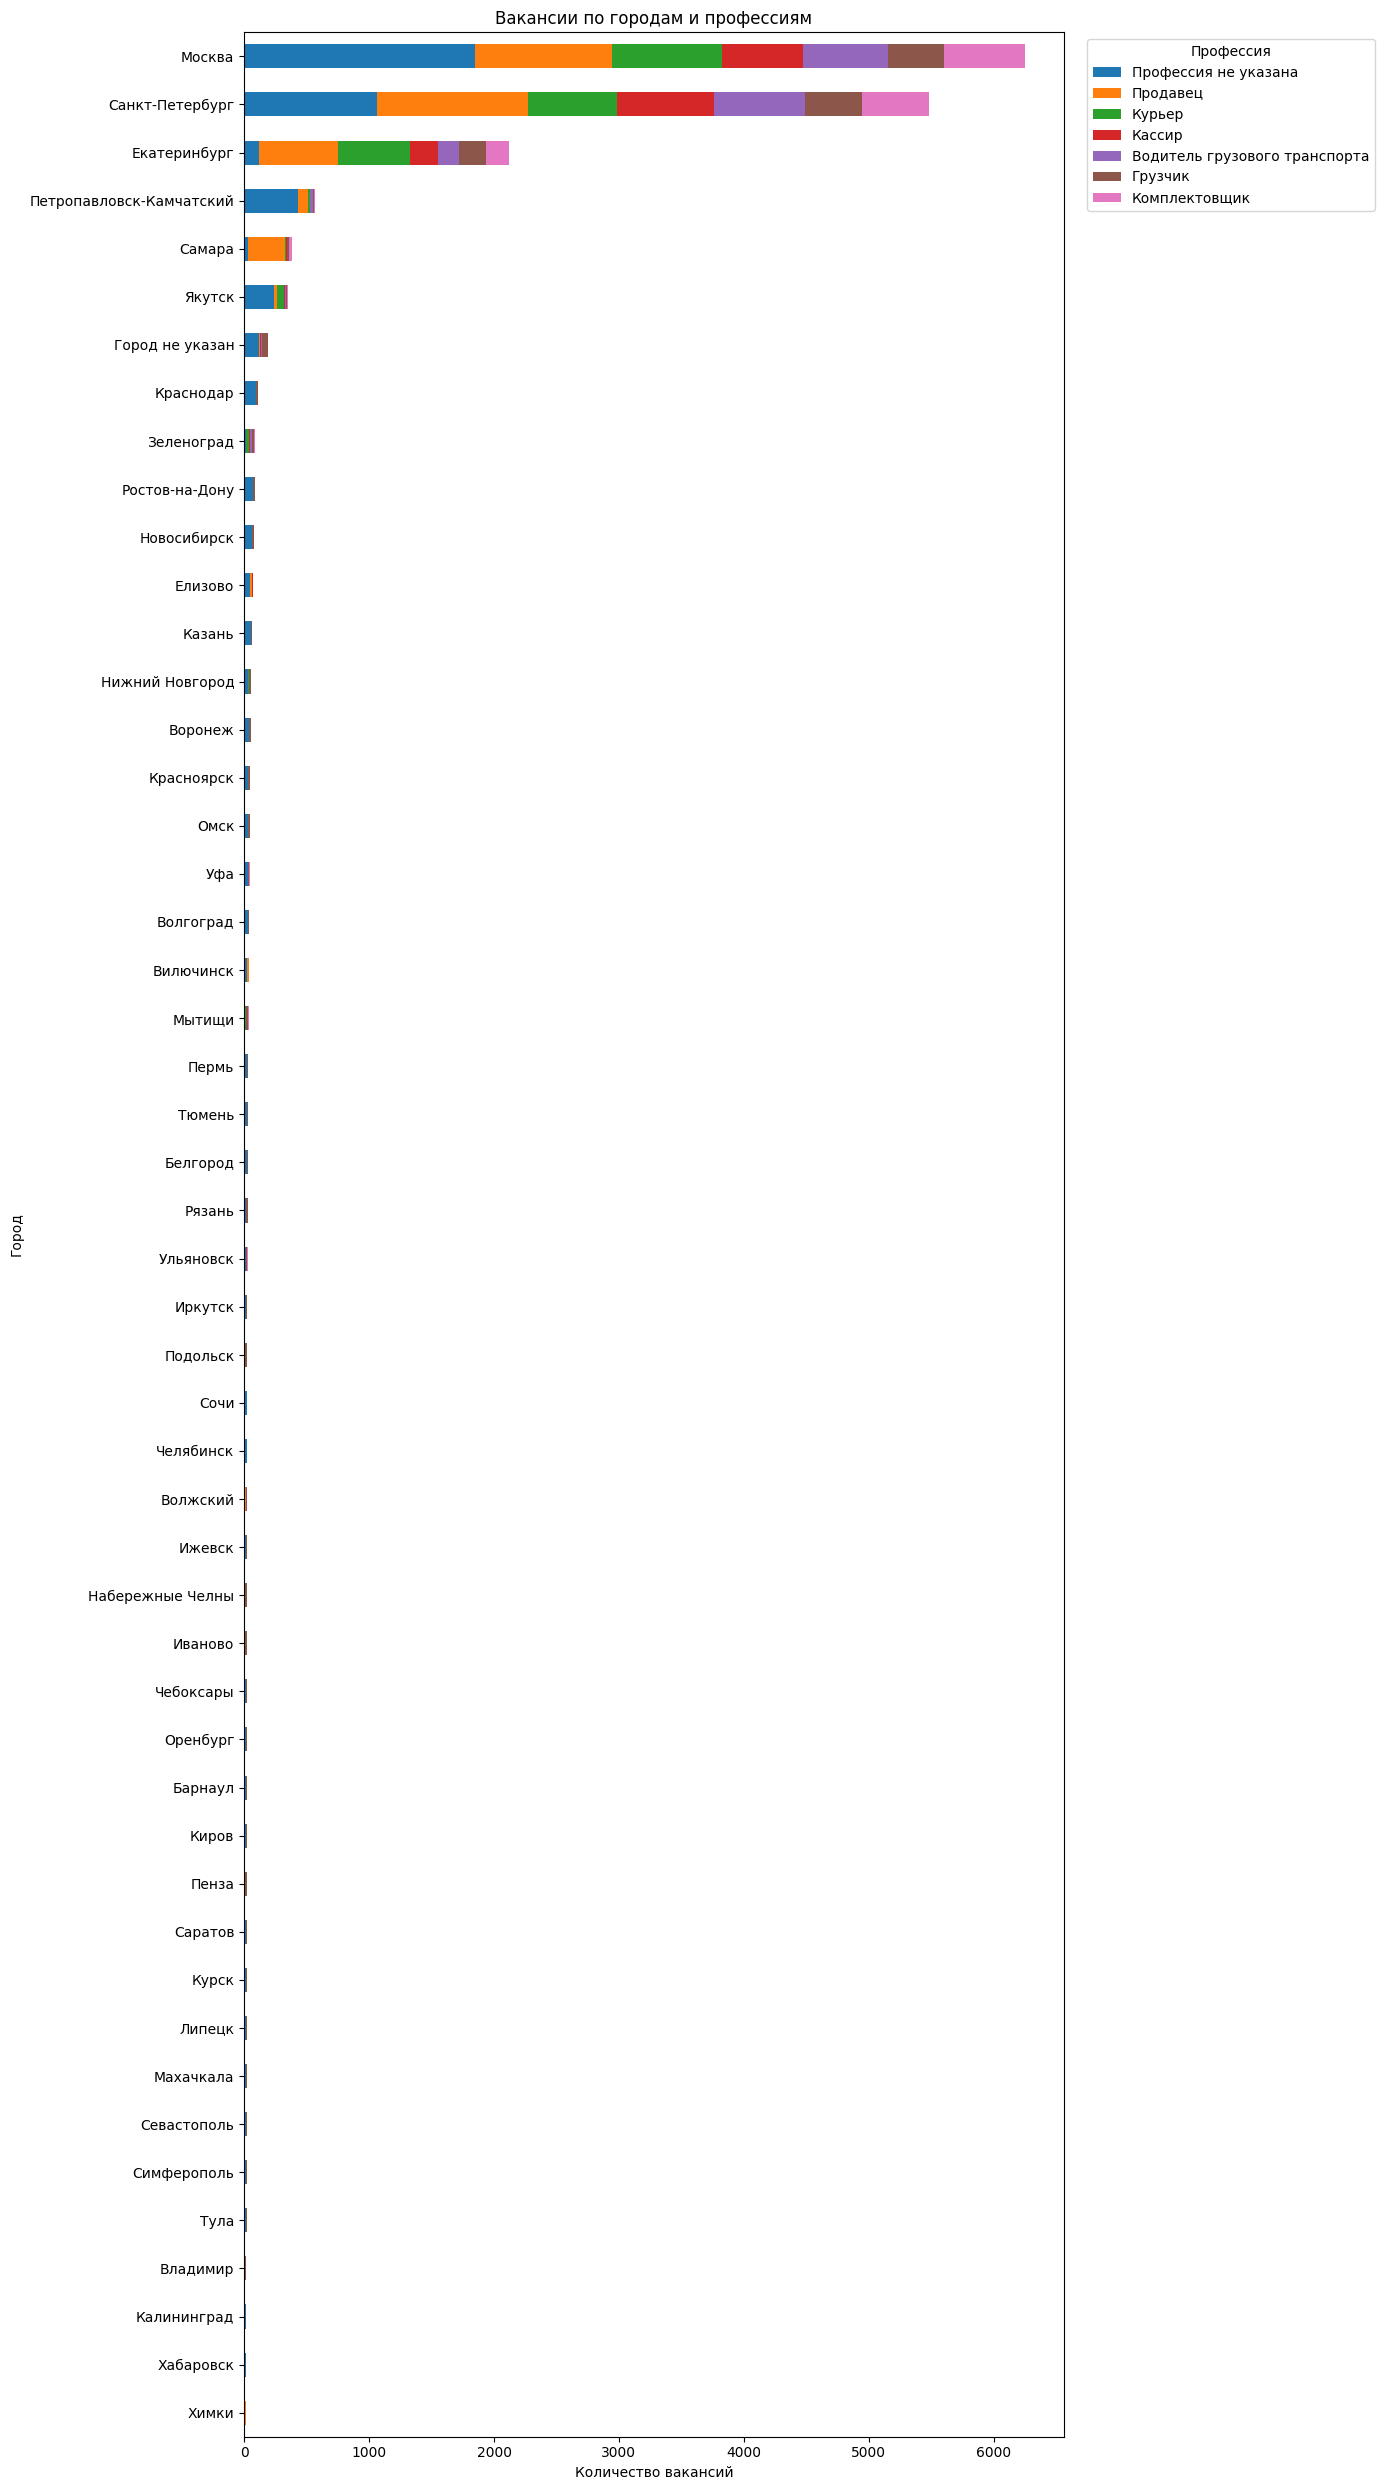

In [212]:
city = df["city_resolved"].fillna("Город не указан")
profession = df["profession_resolved"].fillna("Профессия не указана")

counts = pd.crosstab(city, profession)
top_cities = counts.sum(axis=1).nlargest(50).index
top_professions = counts.sum(axis=0).nlargest(50).index
counts = counts.loc[top_cities, top_professions]
# Сначала города и профессии с наибольшим числом вакансий
counts = counts.loc[
    counts.sum(axis=1).sort_values(ascending=False).index,
    counts.sum(axis=0).sort_values(ascending=False).index,
]


# График 1: точное число вакансий для каждой пары город × профессия
plt.figure(figsize=(16, max(8, len(counts) * 0.55)))
sns.heatmap(counts, annot=True, fmt="d", cmap="Blues", linewidths=0.5)
plt.title("Количество вакансий: город × профессия")
plt.xlabel("Профессия")
plt.ylabel("Город")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# График 2: состав вакансий в каждом городе
ax = counts.iloc[::-1].plot(
    kind="barh",
    stacked=True,
    figsize=(14, max(8, len(counts) * 0.5)),
)
ax.set_title("Вакансии по городам и профессиям")
ax.set_xlabel("Количество вакансий")
ax.set_ylabel("Город")
ax.legend(title="Профессия", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [200]:
import plotly.express as px

counts = (
    df.assign(profession=df["profession_resolved"].fillna("Не указана"))
      .groupby(["salary_unit", "profession_resolved"])
      .size()
      .reset_index(name="vacancies")
)

fig = px.bar(
    counts,
    x="salary_unit",
    y="vacancies",
    color="profession_resolved",
    barmode="group",
    labels={
        "salary_unit": "Формат зарплаты",
        "vacancies": "Количество вакансий",
        "profession_resolved": "Профессия",
    },
    title="Количество вакансий по формату зарплаты и профессии",
)
fig.show()

In [201]:
counts = (
    df.assign(profession_resolved=df["profession_resolved"].fillna("Не указана"))
      .groupby(["profession_resolved", "salary_shape"])
      .size()
      .reset_index(name="vacancies")
)

fig = px.bar(
    counts,
    x="profession_resolved",
    y="vacancies",
    color="salary_shape",
    barmode="group",
    category_orders={
        "salary_shape": ["exact", "range", "from", "to", "unknown"]
    },
    labels={
        "profession_resolved": "Профессия",
        "vacancies": "Количество вакансий",
        "salary_shape": "Формат зарплаты",
    },
    title="Форматы зарплаты по профессиям",
)

fig.update_layout(xaxis_tickangle=-45)
fig.show()

In [202]:
u = df.loc[df["salary_unit"].eq("unspecified") & df["salary_parse_status"].eq("parsed")].copy()

u["value_for_bin"] = np.nan
exact = u["salary_shape"].eq("exact")
interval = u["salary_shape"].eq("range")
from_only = u["salary_shape"].eq("from")
to_only = u["salary_shape"].eq("to")

u.loc[exact | from_only, "value_for_bin"] = u["salary_min_rub"]
u.loc[to_only, "value_for_bin"] = u["salary_max_rub"]
u.loc[interval, "value_for_bin"] = (u["salary_min_rub"] + u["salary_max_rub"]) / 2

u["format"] = u["salary_shape"].map({
    "exact": "Точная сумма",
    "range": "Середина вилки",
    "from": "Нижняя граница «от»",
    "to": "Верхняя граница «до»",
})

bins = [0, 5_000, 10_000, 20_000, 30_000, 50_000,
        75_000, 100_000, 150_000, 200_000, 300_000,
        500_000, np.inf]

labels = ["0–5 тыс.", "5–10 тыс.", "10–20 тыс.", "20–30 тыс.",
          "30–50 тыс.", "50–75 тыс.", "75–100 тыс.",
          "100–150 тыс.", "150–200 тыс.", "200–300 тыс.",
          "300–500 тыс.", "500 тыс.+"]

u["salary_bin"] = pd.cut(
    u["value_for_bin"],
    bins=bins,
    labels=labels,
    right=False,
    include_lowest=True,
)

counts = (u.groupby(["format", "salary_bin"], observed=False).size().reset_index(name="vacancies"))
fig = px.bar(
    counts,
    x="salary_bin",
    y="vacancies",
    facet_col="format",
    facet_col_wrap=2,
    category_orders={"salary_bin": labels},
    labels={
        "salary_bin": "Опубликованная сумма, ₽",
        "vacancies": "Количество вакансий",
    },
    title="Зарплаты без указанного периода: распределение по бинам",
    height=750)
fig.update_xaxes(tickangle=-45)
fig.show()

In [203]:
frequency = (df.loc[df["salary_unit"].eq("unspecified"), "Частота выплат"].astype("string").str.replace("\xa0", " ", regex=False).fillna("Не указана"))
counts = (frequency.value_counts().rename_axis("payment_frequency").reset_index(name="vacancies"))

fig = px.bar(
    counts,
    x="payment_frequency",
    y="vacancies",
    text="vacancies",
    labels={
        "payment_frequency": "Частота выплат",
        "vacancies": "Количество вакансий",
    },
    title="Частота выплат при неуказанном периоде зарплаты")

fig.update_layout(xaxis_tickangle=-35)
fig.show()

In [204]:
frequency = (df.loc[df["salary_unit"].eq("shift"), "Частота выплат"].astype("string").str.replace("\xa0", " ", regex=False).fillna("Не указана"))
counts = (frequency.value_counts().rename_axis("payment_frequency").reset_index(name="vacancies"))

fig = px.bar(
    counts,
    x="payment_frequency",
    y="vacancies",
    text="vacancies",
    labels={
        "payment_frequency": "Частота выплат",
        "vacancies": "Количество вакансий",
    },
    title="Частота выплат shift")

fig.update_layout(xaxis_tickangle=-35)
fig.show()

In [205]:
shift_df = df[df['salary_unit'] == "shift"]
shift_df["Количество рабочих часов в день"].value_counts()

,count
Количество рабочих часов в день,
11–12,1130
"4–5, 6–7, 8, 9–10, 11–12",367
"До 4, 4–5, 6–7, 8, 9–10, 11–12, 13–15",295
"До 4, 4–5, 6–7, 8, 9–10, 11–12",286
"До 4, 4–5, 6–7, 8",233
"8, 9–10, 11–12",180
"9–10, 11–12",179
8,164
9–10,150


In [206]:
df['salary_unit'] = np.where(df['salary_unit'] == "unspecified", "month", df['salary_unit'])
counts = (
    df.assign(profession_resolved=df["profession_resolved"].fillna("Не указана"))
      .groupby(["salary_unit", "profession_resolved"])
      .size()
      .reset_index(name="vacancies")
)

fig = px.bar(
    counts,
    x="salary_unit",
    y="vacancies",
    color="profession_resolved",
    barmode="group",
    labels={
        "salary_unit": "Формат зарплаты",
        "vacancies": "Количество вакансий",
        "profession_resolved": "Профессия",
    },
    title="Количество вакансий по формату зарплаты и профессии",
)
fig.show()

In [207]:
# возьмем середину интервала для оценки c range и нижнюю границу для from
df["salary_point_rub"] = np.where(df["salary_shape"] == "from", df["salary_min_rub"], df[["salary_min_rub", "salary_max_rub"]].mean(axis=1))

print("Форматы зарплаты:")
display(df.groupby(["salary_unit", "salary_shape"]).size().reset_index())


Форматы зарплаты:


,salary_unit,salary_shape,0
0,hour,exact,18
1,hour,from,61
2,hour,range,54
3,hour,to,17
4,month,exact,566
5,month,from,4064
6,month,range,6447
7,month,to,1178
8,month,unknown,499
9,piecework,exact,4


In [208]:
MONTHLY_FACTORS = {
    "month": 1.0,
    "week": 52 / 12,
    "shift": 21,
    "hour": 164,
    "day": 21,
}

df["monthly_factor"] = df["salary_unit"].map(MONTHLY_FACTORS)

df["monthly_min_scenario_rub"] = (df["salary_min_rub"] * df["monthly_factor"])
df["monthly_max_scenario_rub"] = (df["salary_max_rub"] * df["monthly_factor"])
df["monthly_point_scenario_rub"] = (df["salary_point_rub"] * df["monthly_factor"])


ниже только те ваки - по которым получилось достать точный диапазон / конкретное число

In [209]:
df["profession_view"] = df["profession_resolved"].fillna("Не указана")
df["city_view"] = df["city_resolved"].fillna("Не указан")
df["employment_view"] = df["Занятость"].fillna("Не указана")

points = df.loc[df["salary_point_rub"].notna()].copy()



def distribution_by(columns, data, salary_column):
    result = (
        data.groupby(columns, dropna=False)[salary_column]
        .agg(
            n="size",
            q10=lambda x: x.quantile(0.10),
            median="median",
            q90=lambda x: x.quantile(0.90),
        )
        .reset_index()
        .sort_values("n", ascending=False)
    )
    result["мало_данных"] = result["n"] < 30
    return result.round(0)


# 1. Каждая профессия. Единицы оплаты и налоговый статус отдельно
by_profession = distribution_by(
    ["salary_unit", "salary_tax", "profession_view"],
    points,
    "salary_point_rub")

print("Зарплаты по профессиям:")
display(by_profession)

# 2. Города.
by_city = distribution_by(
    ["salary_unit", "salary_tax", "city_view"],
    points,
    "salary_point_rub")

print("Зарплаты по городам:")
display(by_city)

# 3. Профессия × город: для прямого сравнения одной профессии между городами
by_profession_city = distribution_by(
    ["salary_unit", "salary_tax", "profession_view", "city_view"],
    points,
    "salary_point_rub")

print("Профессия × город; показаны группы от 30 вакансий:")
display(by_profession_city.loc[by_profession_city["n"] >= 30])

# 4. Дополнительные разрезы: занятость и график.
by_employment = distribution_by(
    ["salary_unit", "salary_tax", "employment_view"],
    points,
    "salary_point_rub")

by_schedule = distribution_by(
    ["salary_unit", "salary_tax", "График"],
    points,
    "salary_point_rub")

print("По типу занятости:")
display(by_employment)
print("По графику:")
display(by_schedule)

# 5. Сколько вакансий каждой профессии вообще попало в числовой анализ.
coverage = pd.concat(
    [df.groupby("profession_view").size().rename("всего"),
    points.groupby("profession_view").size().rename("с_точечной_суммой")], axis=1,).fillna(0)
coverage["доля_процентов"] = (100 * coverage["с_точечной_суммой"] / coverage["всего"]).round(1)
print("Охват по профессиям:")
display(coverage.sort_values("всего", ascending=False))

Зарплаты по профессиям:


,salary_unit,salary_tax,profession_view,n,q10,median,q90,мало_данных
17,month,net,Не указана,2831,32500.0,95000.0,250000.0,False
25,month,unknown,Продавец,1695,52000.0,75300.0,100000.0,False
24,month,unknown,Не указана,1349,30000.0,85000.0,200000.0,False
12,month,net,Водитель грузового транспорта,963,100000.0,175000.0,308060.0,False
18,month,net,Продавец,933,45000.0,75000.0,120000.0,False
40,shift,net,Курьер,908,4338.0,6920.0,10000.0,False
13,month,net,Грузчик,858,44000.0,75000.0,120000.0,False
37,shift,net,Грузчик,743,2877.0,4400.0,5000.0,False
21,month,unknown,Кассир,633,61470.0,73000.0,105000.0,False
42,shift,net,Продавец,592,2281.0,3750.0,5185.0,False


Зарплаты по городам:


,salary_unit,salary_tax,city_view,n,q10,median,q90,мало_данных
199,month,net,Москва,2322,55000.0,110000.0,300000.0,False
270,month,net,Санкт-Петербург,2018,55000.0,94000.0,200000.0,False
514,month,unknown,Москва,1821,65000.0,95000.0,212400.0,False
563,month,unknown,Санкт-Петербург,1631,60000.0,80000.0,191888.0,False
844,shift,net,Москва,1377,3500.0,4600.0,9200.0,False
...,...,...,...,...,...,...,...,...
3,hour,net,Донецк,1,600.0,600.0,600.0,True
2,hour,net,Губкинский,1,800.0,800.0,800.0,True
1,hour,net,Волгоград,1,2500.0,2500.0,2500.0,True
0,hour,net,Астрахань,1,700.0,700.0,700.0,True


Профессия × город; показаны группы от 30 вакансий:


,salary_unit,salary_tax,profession_view,city_view,n,q10,median,q90,мало_данных
464,month,net,Не указана,Москва,994,35000.0,110000.0,350000.0,False
1026,month,unknown,Продавец,Москва,611,68800.0,90000.0,107500.0,False
1029,month,unknown,Продавец,Санкт-Петербург,556,57640.0,75300.0,95000.0,False
520,month,net,Не указана,Санкт-Петербург,540,40000.0,93500.0,195500.0,False
74,month,net,Водитель грузового транспорта,Москва,421,102000.0,195000.0,350000.0,False
...,...,...,...,...,...,...,...,...,...
1510,shift,unknown,Курьер,Якутск,32,5305.0,7050.0,10000.0,False
666,month,unknown,Грузчик,Екатеринбург,32,55500.0,71400.0,144200.0,False
1463,shift,unknown,Грузчик,Москва,31,3600.0,4200.0,5500.0,False
513,month,net,Не указана,Ростов-на-Дону,30,30000.0,80000.0,132500.0,False


... (2 outputs left out)

По графику:


,salary_unit,salary_tax,График,n,q10,median,q90,мало_данных
10,month,unknown,Сменный,2926,53500.0,79000.0,138600.0,False
8,month,net,Фиксированный,2661,50000.0,100000.0,250000.0,False
6,month,net,Гибкий,2260,30000.0,100000.0,225000.0,False
7,month,net,Сменный,2040,50000.0,83675.0,172000.0,False
17,shift,net,Гибкий,1959,3000.0,5000.0,9200.0,False
18,shift,net,Сменный,1774,2730.0,4000.0,6750.0,False
9,month,unknown,Гибкий,1234,30000.0,100000.0,218010.0,False
11,month,unknown,Фиксированный,1134,42500.0,94750.0,215000.0,False
20,shift,unknown,Гибкий,961,3500.0,6783.0,12392.0,False
21,shift,unknown,Сменный,375,3200.0,5000.0,90000.0,False


Охват по профессиям:


,всего,с_точечной_суммой,доля_процентов
profession_view,,,
Не указана,5515,5148,93.3
Продавец,3430,3392,98.9
Курьер,2323,2317,99.7
Грузчик,2251,2211,98.2
Кассир,1697,1692,99.7
Водитель грузового транспорта,1673,1639,98.0
Комплектовщик,1467,1458,99.4


исходный формат:

(17857, 141)


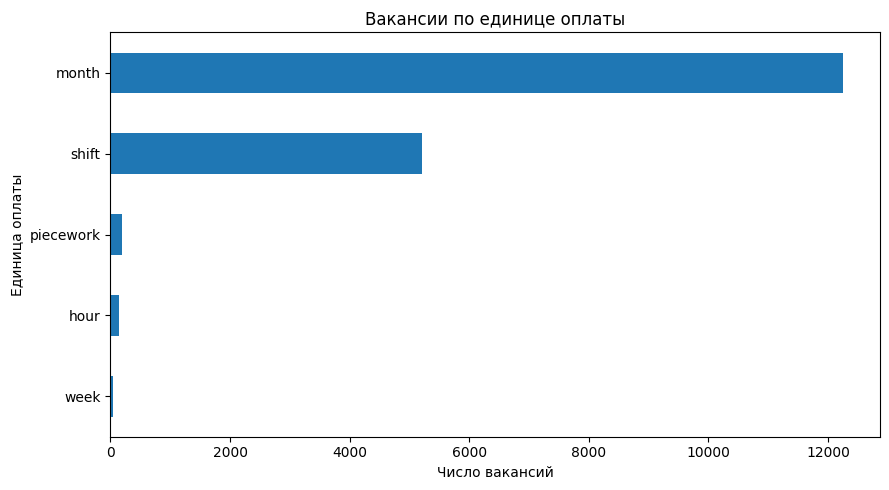

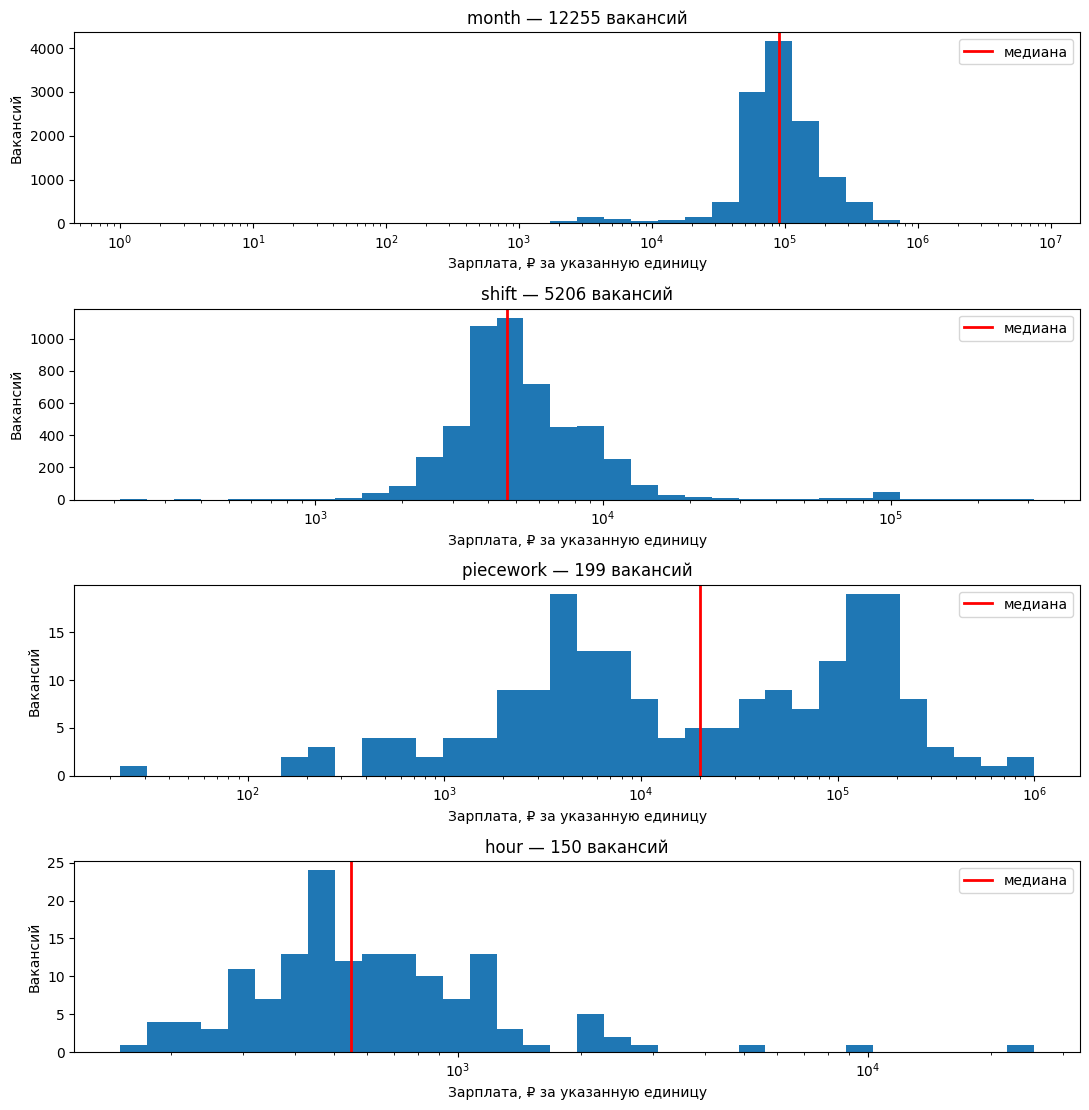

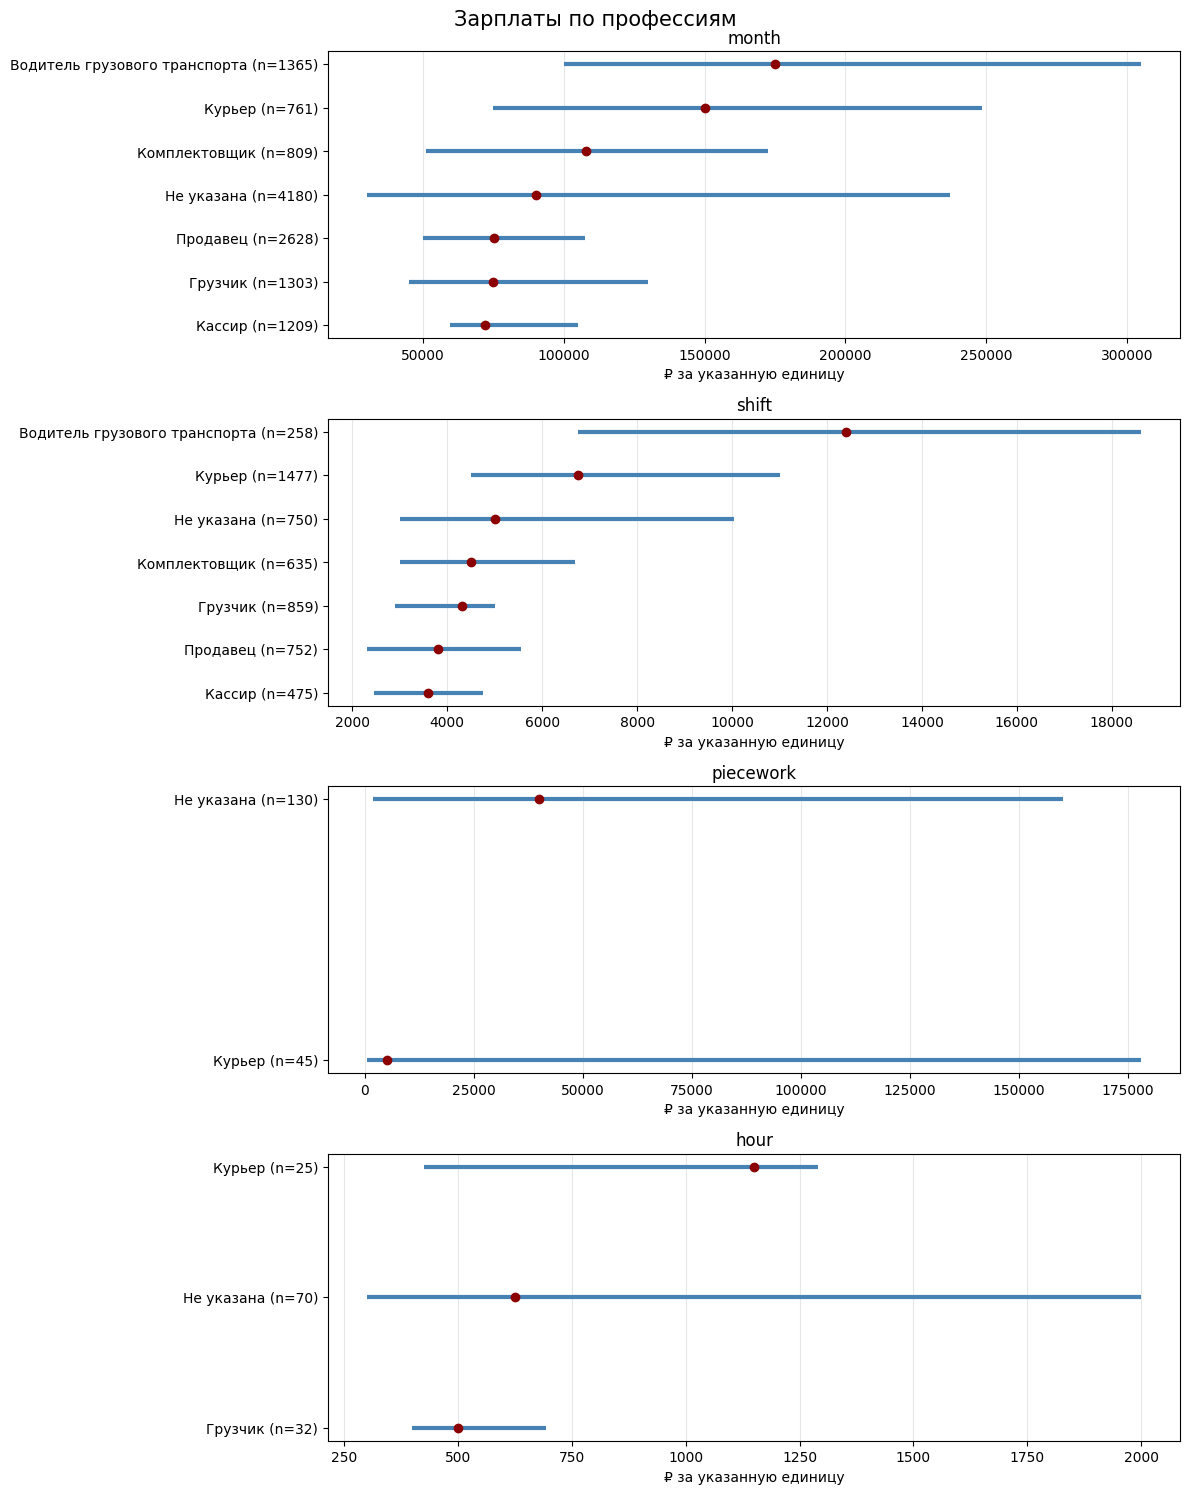

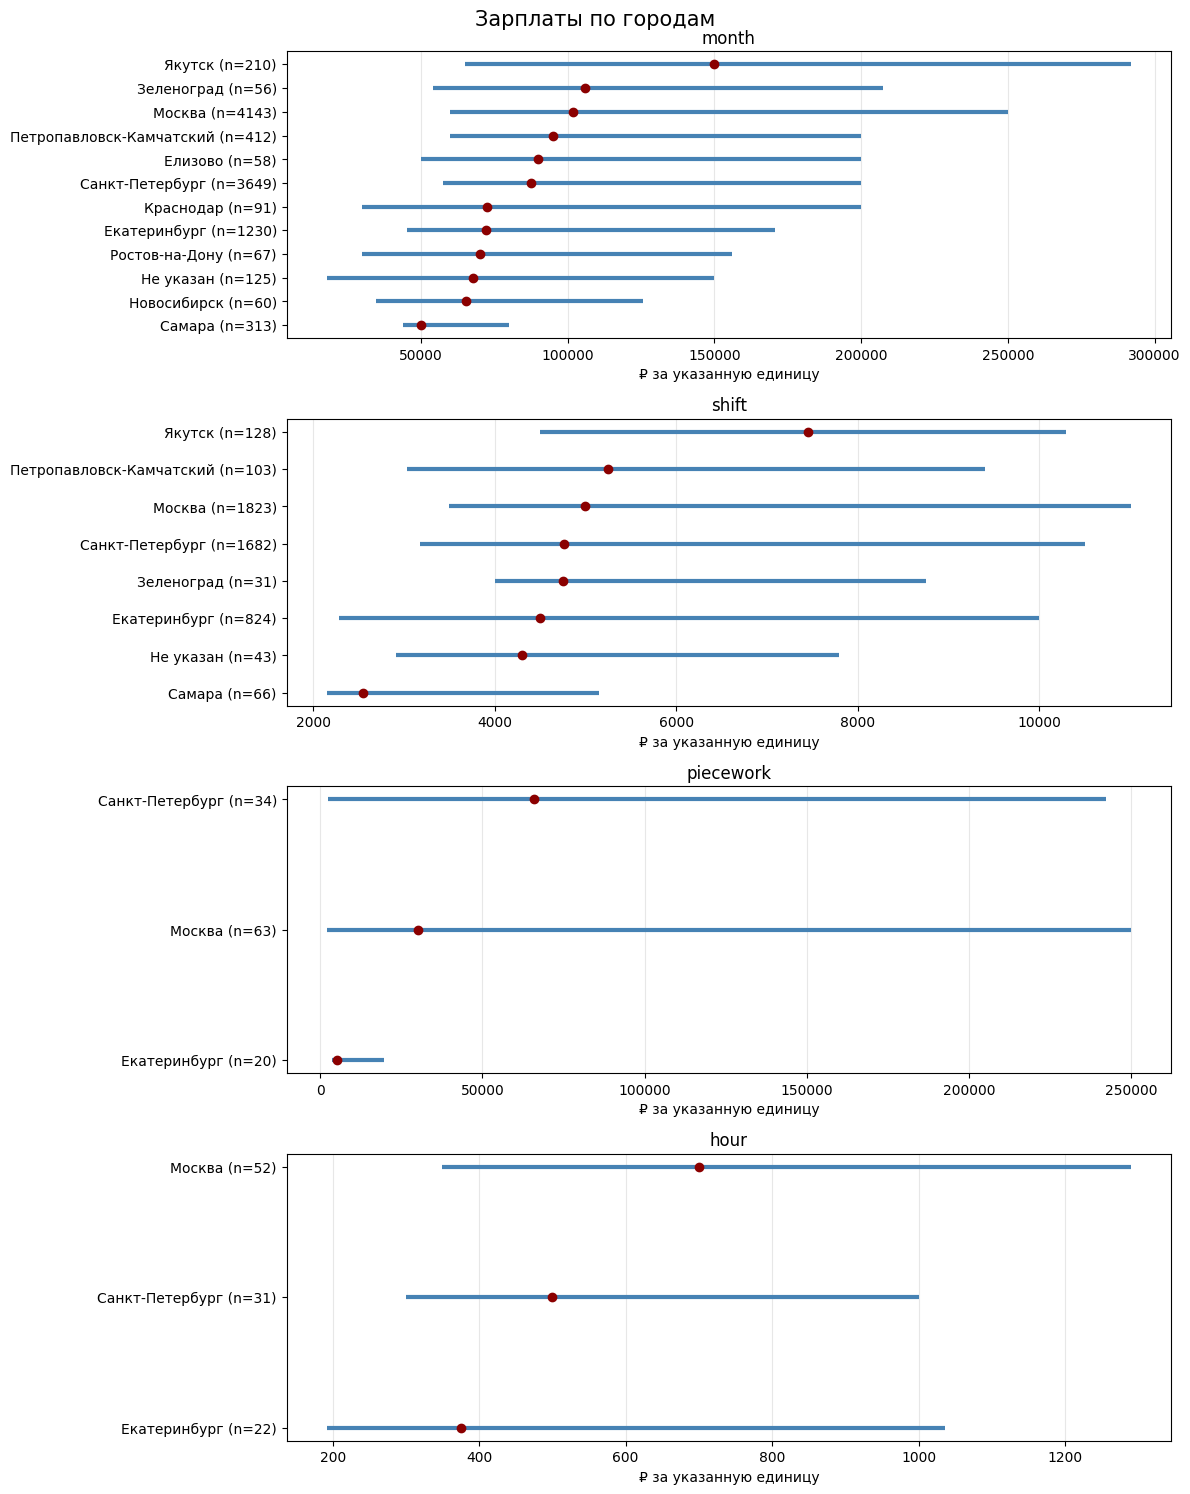

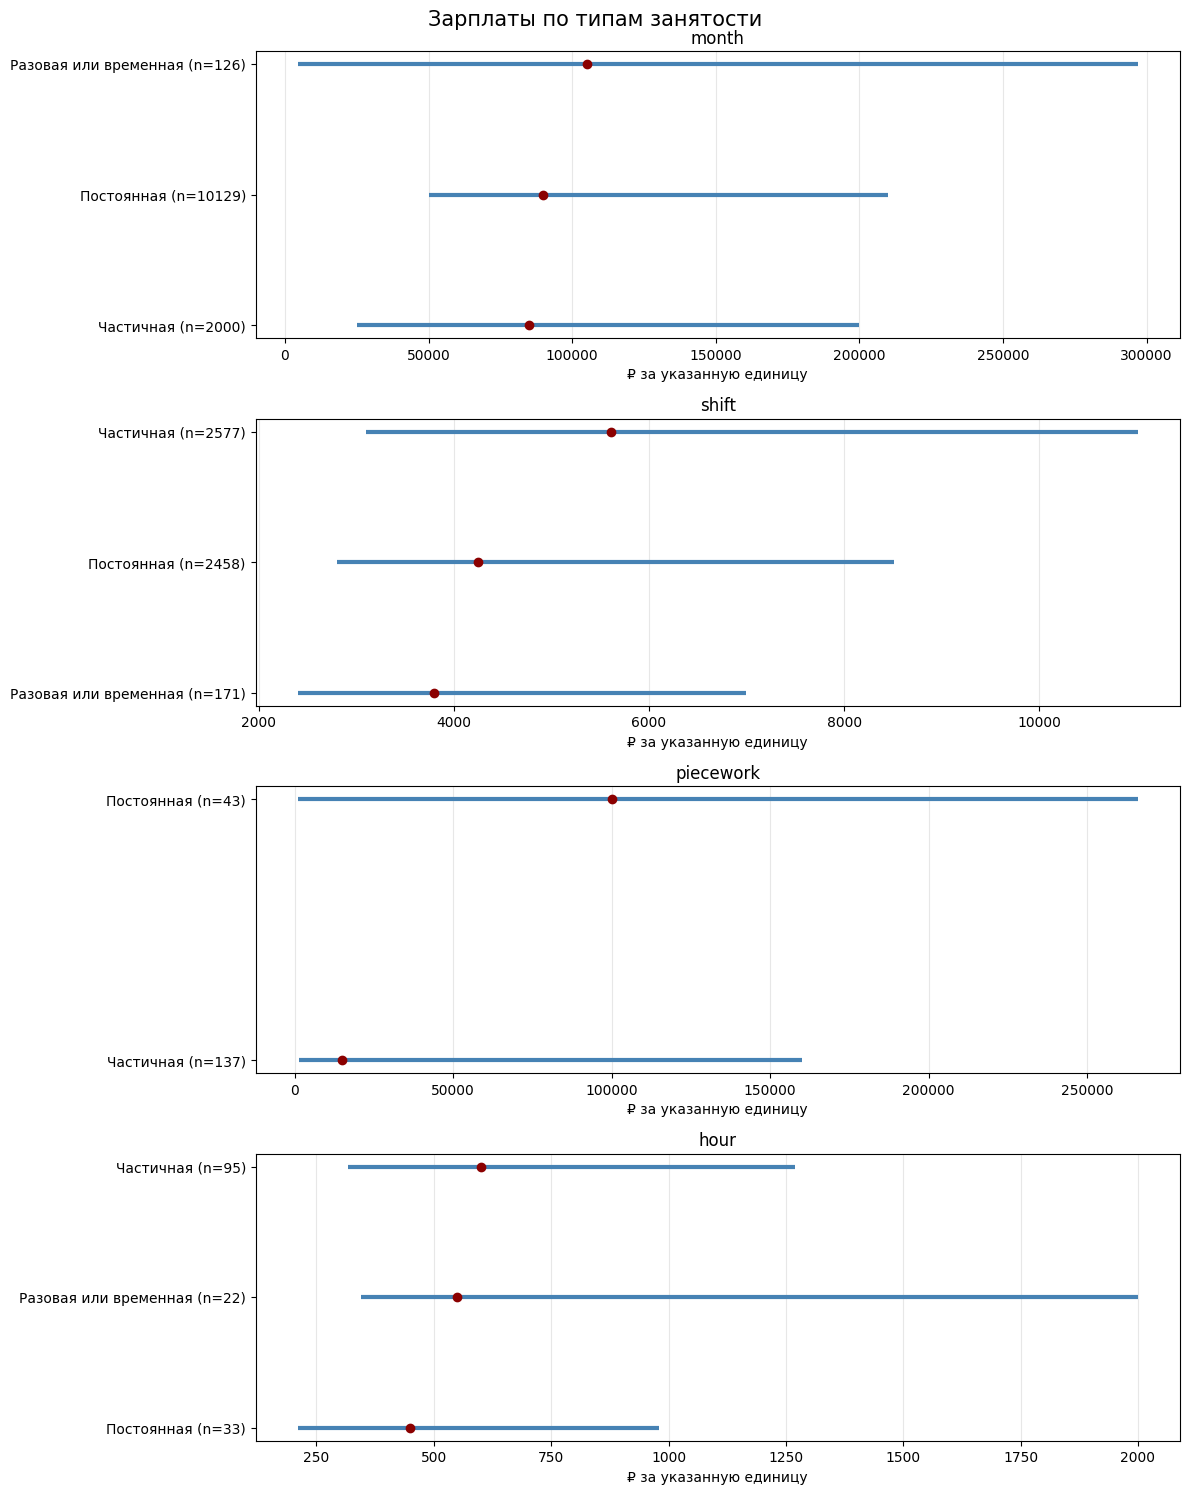

In [210]:
plot_df = df.loc[df["salary_point_rub"].notna()].copy()

print(plot_df.shape)
plot_df["profession_view"] = plot_df["profession_resolved"].fillna("Не указана")
plot_df["city_view"] = plot_df["city_resolved"].fillna("Не указан")
plot_df["employment_view"] = plot_df["Занятость"].fillna("Не указана")

format_counts = (
    plot_df.groupby("salary_unit")
    .size()
    .sort_values(ascending=False)
)
formats = format_counts[format_counts >= 100].index.tolist()

# График 1: сколько вакансий приходится на каждую единицу оплаты
ax = format_counts.sort_values().plot.barh(figsize=(9, 5))
ax.set_title("Вакансии по единице оплаты")
ax.set_xlabel("Число вакансий")
ax.set_ylabel("Единица оплаты")
plt.tight_layout()
plt.show()

# График 2: распределения зарплат
fig, axes = plt.subplots(
    len(formats), 1,
    figsize=(11, 2.8 * len(formats))
)
axes = np.atleast_1d(axes)

for ax, unit in zip(axes, formats):
    x = plot_df.loc[
        plot_df["salary_unit"].eq(unit),
        "salary_point_rub"
    ]
    x = x[x > 0]

    ax.hist(x, bins=np.geomspace(x.min(), x.max(), 35))
    ax.set_xscale("log")
    ax.axvline(x.median(), color="red", linewidth=2, label="медиана")
    ax.set_title(f"{unit} — {len(x)} вакансий")
    ax.set_xlabel("Зарплата, ₽ за указанную единицу")
    ax.set_ylabel("Вакансий")
    ax.legend()

plt.tight_layout()
plt.show()


def plot_quantiles(group_column, title):
    """Отрезок = q10–q90, точка = медиана."""
    fig, axes = plt.subplots(
        len(formats), 1,
        figsize=(12, 3.8 * len(formats))
    )
    axes = np.atleast_1d(axes)

    for ax, unit in zip(axes, formats):
        part = plot_df.loc[plot_df["salary_unit"].eq(unit)]

        stats = (
            part.groupby(group_column)["salary_point_rub"]
            .agg(
                n="size",
                q10=lambda x: x.quantile(0.10),
                median="median",
                q90=lambda x: x.quantile(0.90),
            )
            .reset_index()
        )

        stats = (
            stats.loc[stats["n"] >= 20]
            .sort_values("n", ascending=False)
            .head(12)
            .sort_values("median")
        )

        if stats.empty:
            ax.text(0.5, 0.5, "Мало данных", ha="center", va="center")
            ax.set_axis_off()
            continue

        y = np.arange(len(stats))
        ax.hlines(
            y, stats["q10"], stats["q90"],
            color="steelblue", linewidth=3
        )
        ax.scatter(stats["median"], y, color="darkred", zorder=3)

        ax.set_yticks(y)
        ax.set_yticklabels(
            [
                f"{name} (n={n})"
                for name, n in zip(stats[group_column], stats["n"])
            ]
        )
        ax.set_title(str(unit))
        ax.set_xlabel("₽ за указанную единицу")
        ax.grid(axis="x", alpha=0.3)

    fig.suptitle(title, fontsize=15)
    plt.tight_layout()
    plt.show()


plot_quantiles("profession_view", "Зарплаты по профессиям")
plot_quantiles("city_view", "Зарплаты по городам")
plot_quantiles("employment_view", "Зарплаты по типам занятости")

приводим к месячному формату:

(17658, 141)


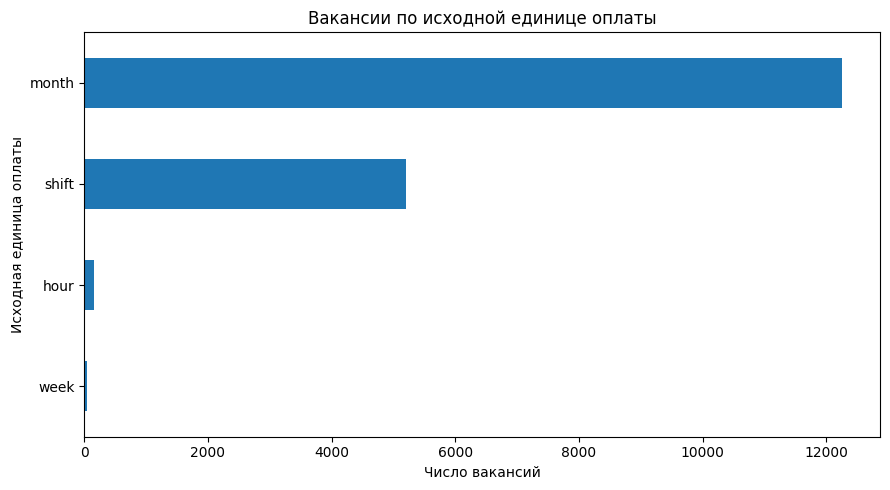

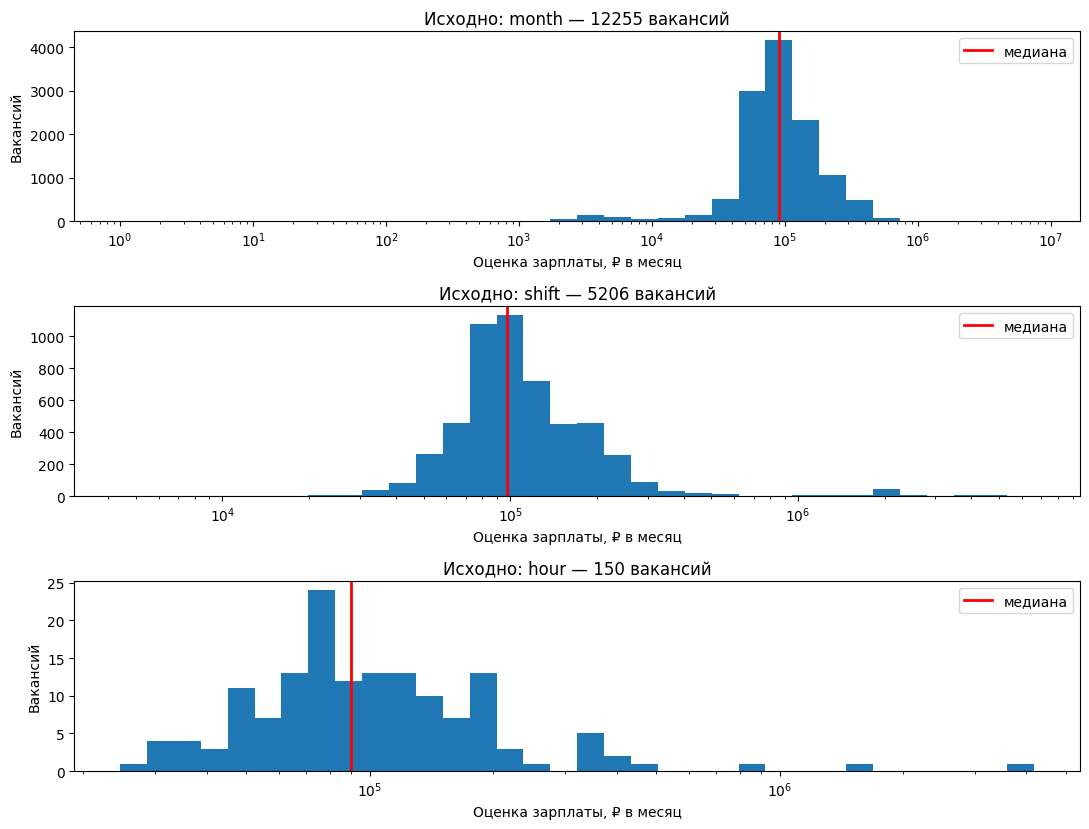

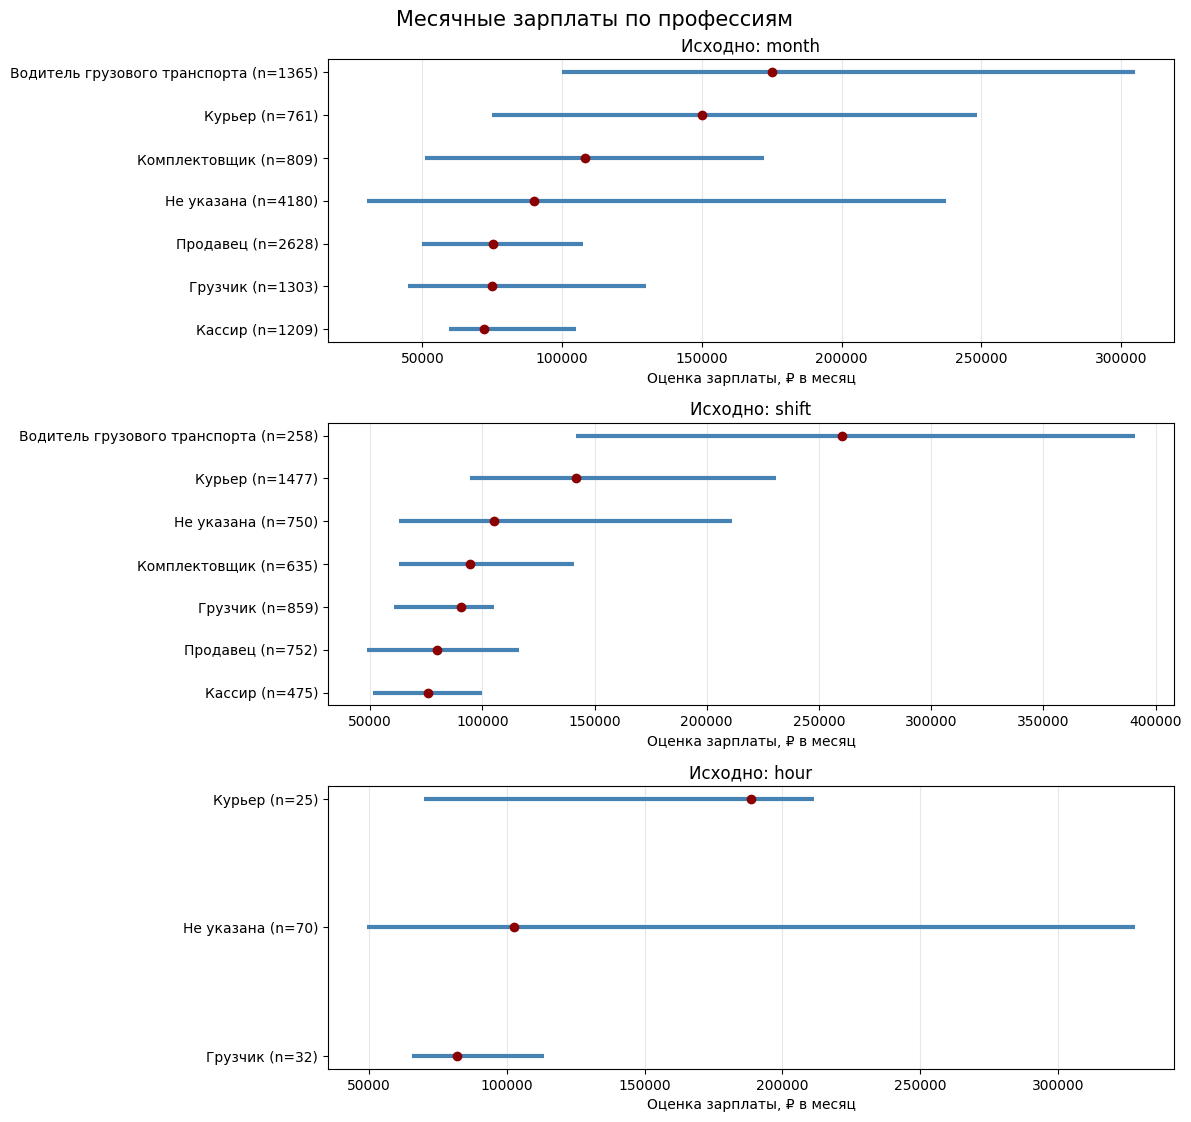

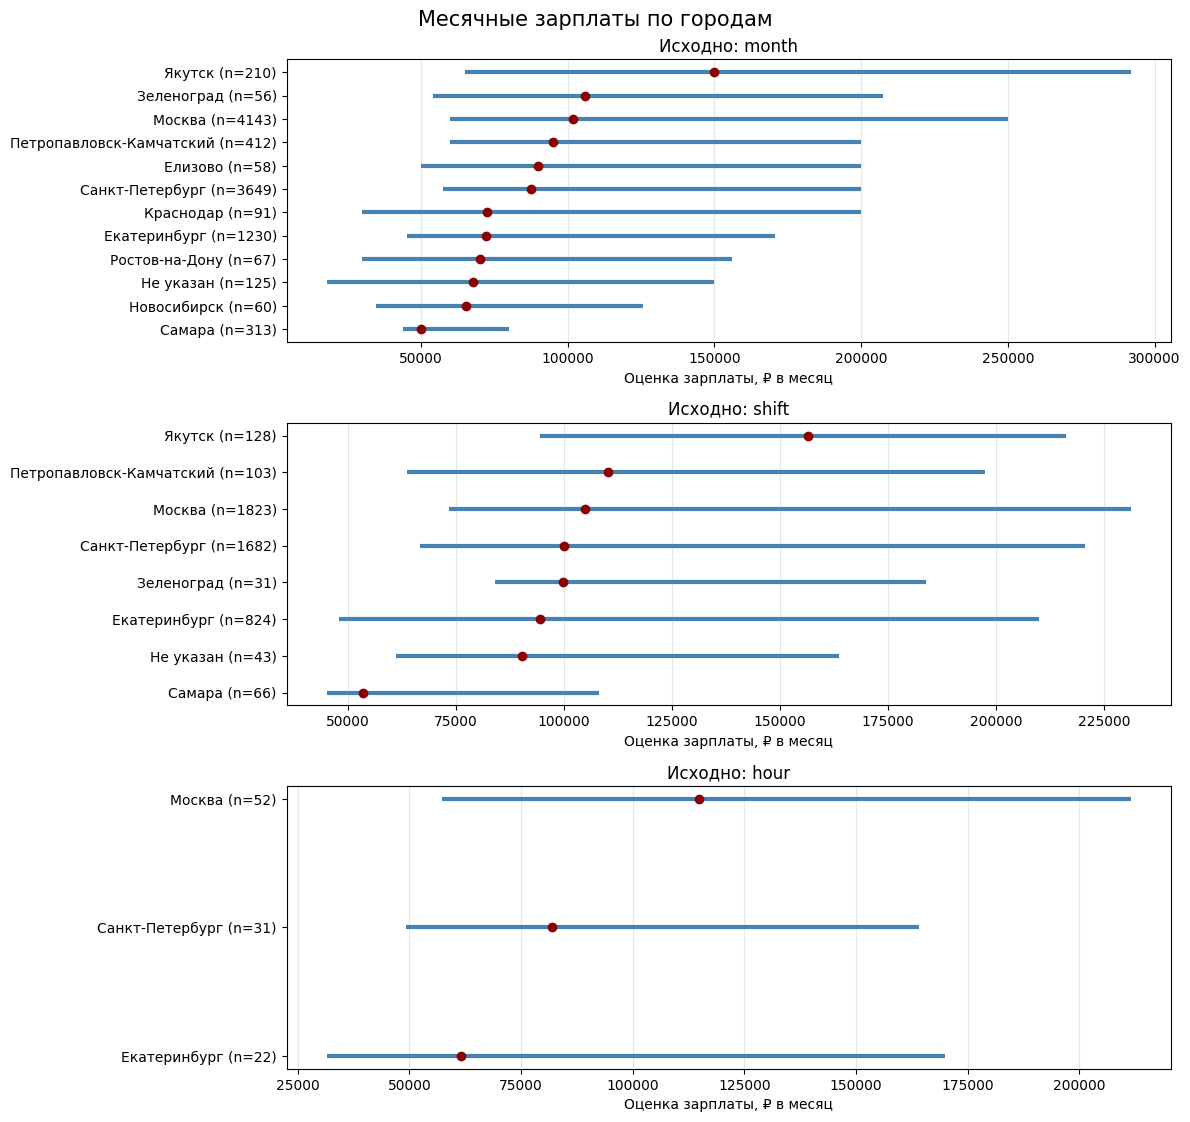

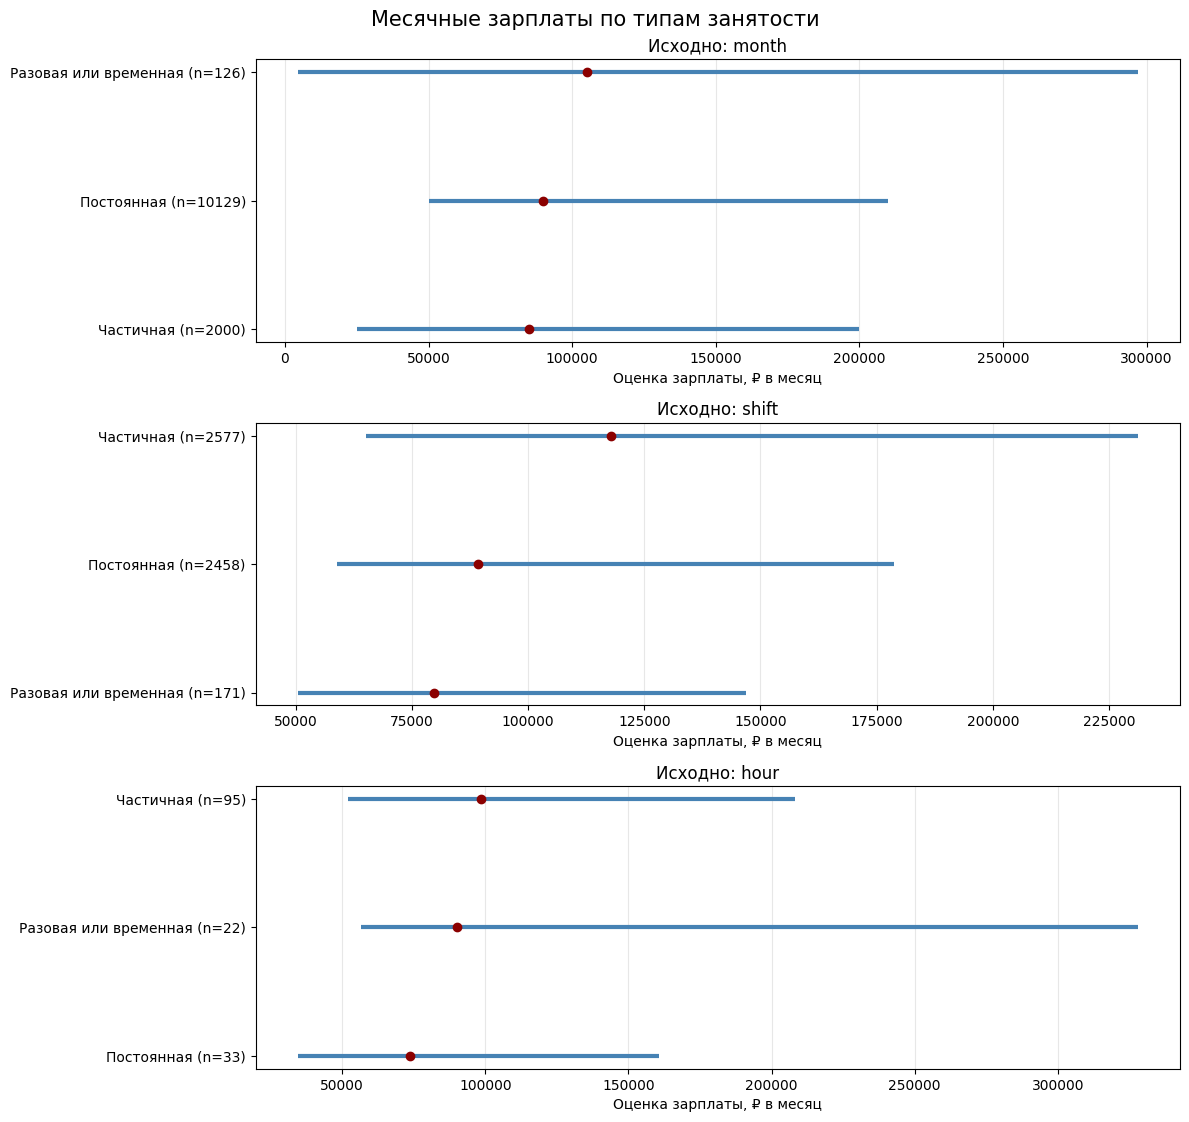

In [211]:
plot_df = df.loc[df["monthly_point_scenario_rub"].notna()].copy()

print(plot_df.shape)
plot_df["profession_view"] = plot_df["profession_resolved"].fillna("Не указана")
plot_df["city_view"] = plot_df["city_resolved"].fillna("Не указан")
plot_df["employment_view"] = plot_df["Занятость"].fillna("Не указана")

format_counts = (
    plot_df.groupby("salary_unit")
    .size()
    .sort_values(ascending=False)
)
formats = format_counts[format_counts >= 100].index.tolist()

# График 1: число вакансий по исходной единице оплаты
ax = format_counts.sort_values().plot.barh(figsize=(9, 5))
ax.set_title("Вакансии по исходной единице оплаты")
ax.set_xlabel("Число вакансий")
ax.set_ylabel("Исходная единица оплаты")
plt.tight_layout()
plt.show()

# График 2: распределение месячных зарплат
fig, axes = plt.subplots(
    len(formats), 1,
    figsize=(11, 2.8 * len(formats))
)
axes = np.atleast_1d(axes)

for ax, unit in zip(axes, formats):
    x = plot_df.loc[
        plot_df["salary_unit"].eq(unit),
        "monthly_point_scenario_rub"
    ]
    x = x[x > 0]

    ax.hist(x, bins=np.geomspace(x.min(), x.max(), 35))
    ax.set_xscale("log")
    ax.axvline(x.median(), color="red", linewidth=2, label="медиана")
    ax.set_title(f"Исходно: {unit} — {len(x)} вакансий")
    ax.set_xlabel("Оценка зарплаты, ₽ в месяц")
    ax.set_ylabel("Вакансий")
    ax.legend()

plt.tight_layout()
plt.show()


def plot_quantiles(group_column, title):
    """Отрезок = q10–q90, точка = медиана."""
    fig, axes = plt.subplots(
        len(formats), 1,
        figsize=(12, 3.8 * len(formats))
    )
    axes = np.atleast_1d(axes)

    for ax, unit in zip(axes, formats):
        part = plot_df.loc[plot_df["salary_unit"].eq(unit)]

        stats = (
            part.groupby(group_column)["monthly_point_scenario_rub"]
            .agg(
                n="size",
                q10=lambda x: x.quantile(0.10),
                median="median",
                q90=lambda x: x.quantile(0.90),
            )
            .reset_index()
        )

        stats = (
            stats.loc[stats["n"] >= 20]
            .sort_values("n", ascending=False)
            .head(12)
            .sort_values("median")
        )

        if stats.empty:
            ax.text(0.5, 0.5, "Мало данных", ha="center", va="center")
            ax.set_axis_off()
            continue

        y = np.arange(len(stats))
        ax.hlines(
            y, stats["q10"], stats["q90"],
            color="steelblue", linewidth=3
        )
        ax.scatter(stats["median"], y, color="darkred", zorder=3)

        ax.set_yticks(y)
        ax.set_yticklabels(
            [
                f"{name} (n={n})"
                for name, n in zip(stats[group_column], stats["n"])
            ]
        )
        ax.set_title(f"Исходно: {unit}")
        ax.set_xlabel("Оценка зарплаты, ₽ в месяц")
        ax.grid(axis="x", alpha=0.3)

    fig.suptitle(title, fontsize=15)
    plt.tight_layout()
    plt.show()


plot_quantiles("profession_view", "Месячные зарплаты по профессиям")
plot_quantiles("city_view", "Месячные зарплаты по городам")
plot_quantiles("employment_view", "Месячные зарплаты по типам занятости")

распредления ЗП

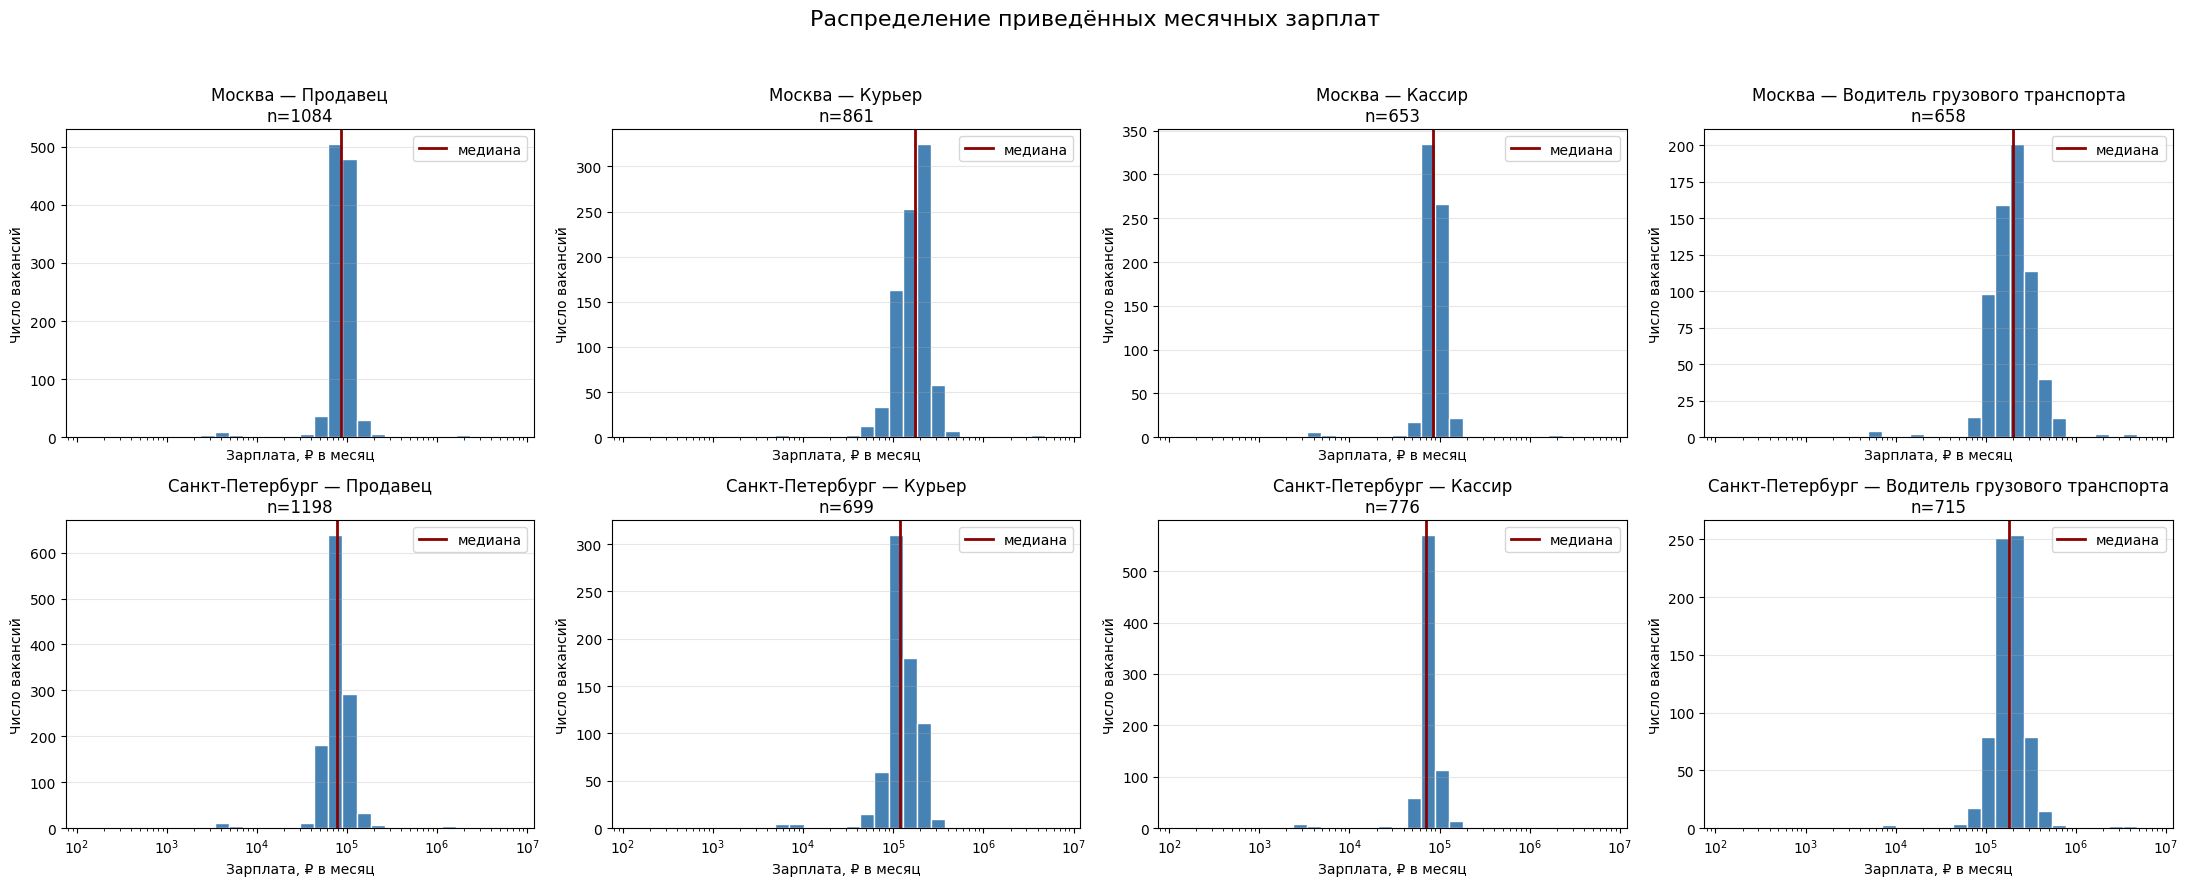

In [213]:
salary_col = "monthly_point_scenario_rub"
cities = ["Москва", "Санкт-Петербург"]
professions = [
    "Продавец",
    "Курьер",
    "Кассир",
    "Водитель грузового транспорта",
]

plot_df = df.loc[df[salary_col].gt(0)].copy()

plot_df["city_key"] = (
    plot_df["city_resolved"]
    .astype("string")
    .str.strip()
    .str.casefold()
    .replace({
        "спб": "санкт-петербург",
        "питер": "санкт-петербург",
        "санкт петербург": "санкт-петербург",
    })
)
plot_df["profession_key"] = (
    plot_df["profession_resolved"]
    .astype("string")
    .str.strip()
    .str.casefold()
)

selected = plot_df.loc[
    plot_df["city_key"].isin([city.casefold() for city in cities])
    & plot_df["profession_key"].isin(
        [profession.casefold() for profession in professions]
    )
]

if selected.empty:
    raise ValueError("Нет данных для выбранных городов и профессий")

min_salary = selected[salary_col].min()
max_salary = selected[salary_col].max()

if min_salary == max_salary:
    min_salary *= 0.9
    max_salary *= 1.1

bins = np.geomspace(min_salary, max_salary, 31)

fig, axes = plt.subplots(2, 4, figsize=(22, 9), sharex=True)

for row, city in enumerate(cities):
    for col, profession in enumerate(professions):
        ax = axes[row, col]

        salaries = selected.loc[
            selected["city_key"].eq(city.casefold())
            & selected["profession_key"].eq(profession.casefold()),
            salary_col,
        ]

        if salaries.empty:
            ax.text(0.5, 0.5, "Нет данных",
                    ha="center", va="center", transform=ax.transAxes)
        else:
            ax.hist(salaries, bins=bins, color="steelblue", edgecolor="white")
            ax.axvline(
                salaries.median(),
                color="darkred",
                linewidth=2,
                label="медиана",
            )
            ax.legend()

        ax.set_xscale("log")
        ax.set_title(f"{city} — {profession}\nn={len(salaries)}")
        ax.set_xlabel("Зарплата, ₽ в месяц")
        ax.set_ylabel("Число вакансий")
        ax.grid(axis="y", alpha=0.3)

fig.suptitle("Распределение приведённых месячных зарплат", fontsize=16)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()